In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("phone_usage_feature_engineered.csv")

df.head()

,Age,Gender,Location,Phone Brand,OS,Screen Time (hrs/day),Data Usage (GB/month),Calls Duration (mins/day),Number of Apps Installed,Social Media Time (hrs/day),E-commerce Spend (INR/month),Streaming Time (hrs/day),Gaming Time (hrs/day),Monthly Recharge Cost (INR),Primary Use,Entertainment_Index,Spend_Ratio
0,53,Male,Mumbai,Vivo,Android,3.7,23.9,37.9,104,3.9,469,5.2,4.1,803,Education,4.400000,0.583333
1,60,Other,Delhi,Realme,iOS,9.2,28.1,13.7,169,2.8,4997,5.1,0.4,1526,Gaming,2.766667,3.272430
2,37,Female,Ahmedabad,Nokia,Android,4.5,12.3,66.8,96,3.0,2381,1.7,2.9,1619,Entertainment,2.533333,1.469753
3,32,Male,Pune,Samsung,Android,11.0,25.6,156.2,146,5.2,1185,3.2,0.3,1560,Entertainment,2.900000,0.759129
4,16,Male,Mumbai,Xiaomi,iOS,2.2,2.5,236.2,86,5.5,106,3.4,2.3,742,Social Media,3.733333,0.142665


In [4]:
print(df.columns.tolist())

['Age', 'Gender', 'Location', 'Phone Brand', 'OS', 'Screen Time (hrs/day)', 'Data Usage (GB/month)', 'Calls Duration (mins/day)', 'Number of Apps Installed', 'Social Media Time (hrs/day)', 'E-commerce Spend (INR/month)', 'Streaming Time (hrs/day)', 'Gaming Time (hrs/day)', 'Monthly Recharge Cost (INR)', 'Primary Use', 'Entertainment_Index', 'Spend_Ratio']


In [7]:
X = df.drop("Primary Use", axis=1)
y = df["Primary Use"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (17686, 16)
y shape: (17686,)


In [8]:
df.shape

(17686, 17)

In [9]:
#Identify categorical and numerical columns
X.dtypes

Age                               int64
Gender                           object
Location                         object
Phone Brand                      object
OS                               object
Screen Time (hrs/day)           float64
Data Usage (GB/month)           float64
Calls Duration (mins/day)       float64
Number of Apps Installed          int64
Social Media Time (hrs/day)     float64
E-commerce Spend (INR/month)      int64
Streaming Time (hrs/day)        float64
Gaming Time (hrs/day)           float64
Monthly Recharge Cost (INR)       int64
Entertainment_Index             float64
Spend_Ratio                     float64
dtype: object

In [10]:
categorical_cols = [
    "Gender",
    "Location",
    "Phone Brand",
    "OS"
]

numerical_cols = [
    "Age",
    "Screen Time (hrs/day)",
    "Data Usage (GB/month)",
    "Calls Duration (mins/day)",
    "Number of Apps Installed",
    "Social Media Time (hrs/day)",
    "E-commerce Spend (INR/month)",
    "Streaming Time (hrs/day)",
    "Gaming Time (hrs/day)",
    "Monthly Recharge Cost (INR)",
    "Entertainment_Index",
    "Spend_Ratio"
]

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['Gender', 'Location', 'Phone Brand', 'OS']
Numerical columns: ['Age', 'Screen Time (hrs/day)', 'Data Usage (GB/month)', 'Calls Duration (mins/day)', 'Number of Apps Installed', 'Social Media Time (hrs/day)', 'E-commerce Spend (INR/month)', 'Streaming Time (hrs/day)', 'Gaming Time (hrs/day)', 'Monthly Recharge Cost (INR)', 'Entertainment_Index', 'Spend_Ratio']


In [11]:
#label encode target
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print(label_encoder.classes_)

['Education' 'Entertainment' 'Gaming' 'Social Media' 'Work']


In [12]:
#Train/test split
#Because this is multiclass classification, use a stratified split so that the five Primary Use categories remain represented similarly in both datasets.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [14]:
#Preprocessing - encoding
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [15]:
#Logistic Regression

#Because we have five classes, Logistic Regression will automatically handle this as a multiclass classification problem.
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, classification_report

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

#train the model
logistic_model.fit(X_train, y_train)

#predict
y_pred_logistic = logistic_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_logistic))

print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

Accuracy: 0.19587337478801584
              precision    recall  f1-score   support

           0       0.19      0.20      0.19       721
           1       0.19      0.17      0.18       690
           2       0.19      0.23      0.21       715
           3       0.21      0.16      0.19       700
           4       0.20      0.21      0.21       712

    accuracy                           0.20      3538
   macro avg       0.20      0.20      0.20      3538
weighted avg       0.20      0.20      0.20      3538



In [16]:
#DecisionTree
#Create the Decision Tree pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

decision_tree_model.fit(X_train, y_train)
y_pred_tree = decision_tree_model.predict(X_test)


print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_tree))

print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.19756924816280386
              precision    recall  f1-score   support

           0       0.21      0.19      0.20       721
           1       0.19      0.20      0.19       690
           2       0.21      0.22      0.21       715
           3       0.21      0.20      0.20       700
           4       0.17      0.18      0.18       712

    accuracy                           0.20      3538
   macro avg       0.20      0.20      0.20      3538
weighted avg       0.20      0.20      0.20      3538



In [17]:
#random forest
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.2018089315997739
              precision    recall  f1-score   support

           0       0.21      0.25      0.23       721
           1       0.20      0.19      0.19       690
           2       0.22      0.24      0.23       715
           3       0.19      0.17      0.18       700
           4       0.18      0.17      0.18       712

    accuracy                           0.20      3538
   macro avg       0.20      0.20      0.20      3538
weighted avg       0.20      0.20      0.20      3538



In [18]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="multi:softmax",
        num_class=5,
        n_estimators=100,
        random_state=42,
        eval_metric="mlogloss"
    ))
])

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print(
    classification_report(
        y_test,
        y_pred_xgb
    )
)

XGBoost Accuracy: 0.20407009609949123
              precision    recall  f1-score   support

           0       0.21      0.20      0.21       721
           1       0.18      0.19      0.19       690
           2       0.23      0.23      0.23       715
           3       0.20      0.20      0.20       700
           4       0.19      0.20      0.20       712

    accuracy                           0.20      3538
   macro avg       0.20      0.20      0.20      3538
weighted avg       0.20      0.20      0.20      3538



The four classification models showed limited ability to predict Primary Use from the available phone-usage and demographic features. All models achieved approximately 20% accuracy, which is close to the expected baseline for the five balanced classes.

In [22]:
print(label_encoder.classes_)

['Education' 'Entertainment' 'Gaming' 'Social Media' 'Work']


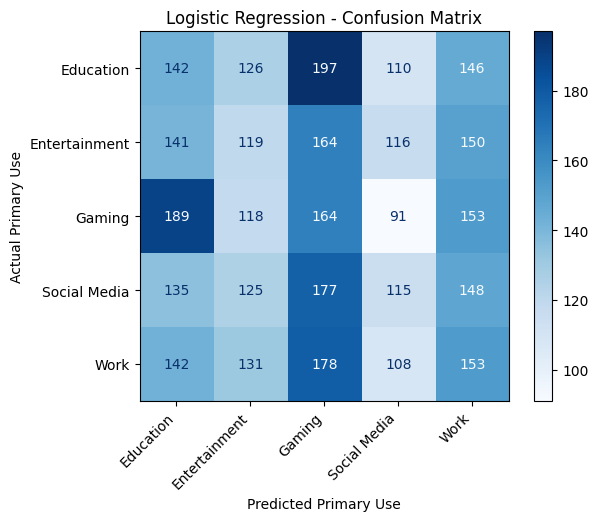

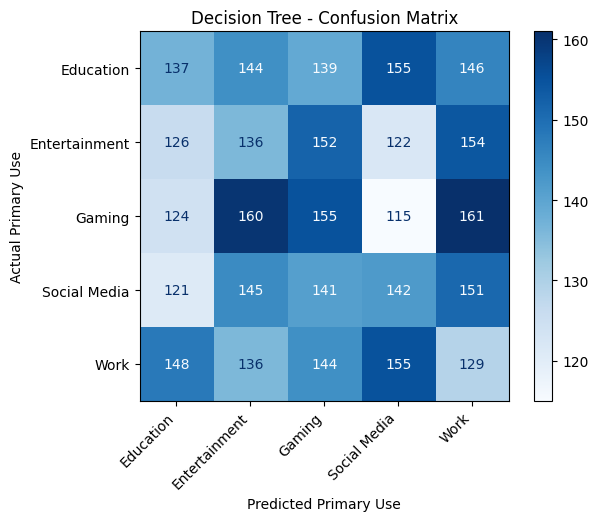

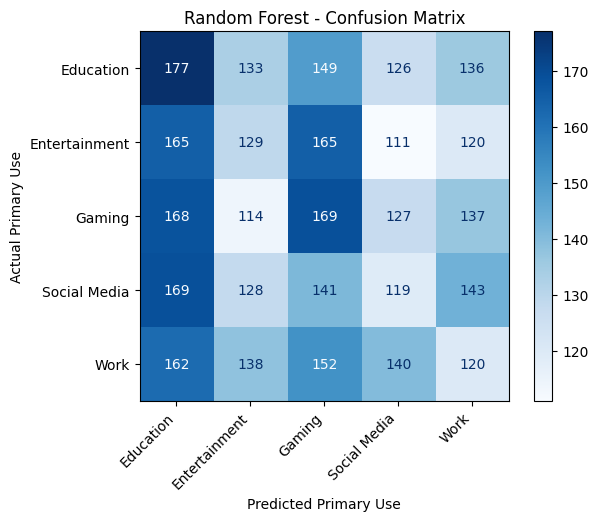

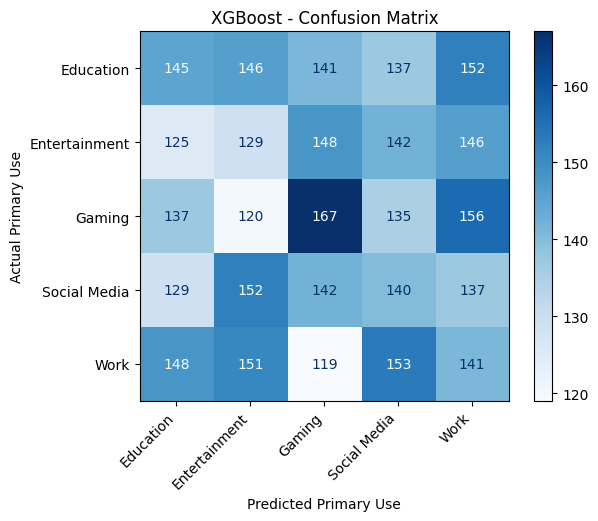

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for model_name, y_pred in models.items():

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
      
    )

    disp.plot(cmap="Blues")
    plt.xticks(rotation=45, ha="right")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Primary Use")
    plt.ylabel("Actual Primary Use")
    plt.show()

| Model               | Overall accuracy | Main observation                                           |
| ------------------- | ---------------: | ---------------------------------------------------------- |
| Logistic Regression |             ~20% | Tends to predict Gaming relatively often                   |
| Decision Tree       |             ~20% | Substantial confusion among all classes                    |
| Random Forest       |             ~20% | Education/Gaming somewhat better; Work/Social Media weaker |
| XGBoost             |       **20.41%** | Predictions are relatively evenly distributed              |

The important conclusion

Across all four confusion matrices, there is no strong diagonal pattern.

Four classification models—Logistic Regression, Decision Tree, Random Forest, and XGBoost—were trained to predict users' Primary Use category. All four models achieved accuracies close to the 20% baseline expected for a five-class classification problem. The confusion matrices showed substantial overlap between Education, Entertainment, Gaming, Social Media, and Work, with no strong diagonal pattern indicating reliable class separation. Although Random Forest showed somewhat stronger recognition for some classes and XGBoost achieved an accuracy of 20.41%, overall predictive performance remained limited. These results suggest that the current set of predictors does not provide sufficient discriminative information for the models to reliably predict Primary Use.

In [ ]:
#Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Models and parameter grids
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=42),
        {
            "model__C": [0.1, 1, 10],
            "model__solver": ["lbfgs"]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "model__max_depth": [5, 10, 20, None],
            "model__min_samples_split": [2, 5, 10]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_split": [2, 5]
        }
    ),

    "XGBoost": (
        XGBClassifier(
            random_state=42,
            eval_metric="mlogloss"
        ),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [3, 6],
            "model__learning_rate": [0.05, 0.1]
        }
    )
}

In [37]:
tuned_models = {}
tuning_results = {}

for name, (model, param_grid) in models.items():

    print(f"\nTuning {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid_search = GridSearchCV(
        pipeline,
        param_grid,
        cv=3,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuned_models[name] = grid_search.best_estimator_

    tuning_results[name] = {
        "Best CV Accuracy": grid_search.best_score_,
        "Test Accuracy": grid_search.score(X_test, y_test),
        "Best Parameters": grid_search.best_params_
    }

    print("Best CV Accuracy:", grid_search.best_score_)
    print("Test Accuracy:", grid_search.score(X_test, y_test))
    print("Best Parameters:", grid_search.best_params_)


Tuning Logistic Regression...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best CV Accuracy: 0.20872208085948543
Test Accuracy: 0.19559072922555115
Best Parameters: {'model__C': 10, 'model__solver': 'lbfgs'}

Tuning Decision Tree...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV Accuracy: 0.2002403166525304
Test Accuracy: 0.2052006783493499
Best Parameters: {'model__max_depth': 5, 'model__min_samples_split': 10}

Tuning Random Forest...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best CV Accuracy: 0.20532937517670344
Test Accuracy: 0.21113623516110797
Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Tuning XGBoost...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV Accuracy: 0.20603618886061634
Test Accuracy: 0.19361221028829848
Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 6, 'model__n_estimators': 200}


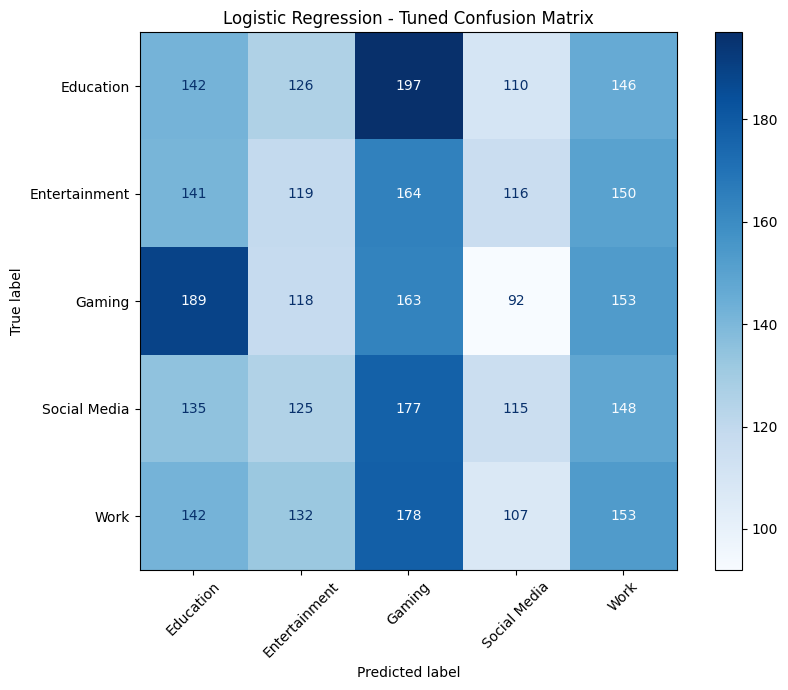

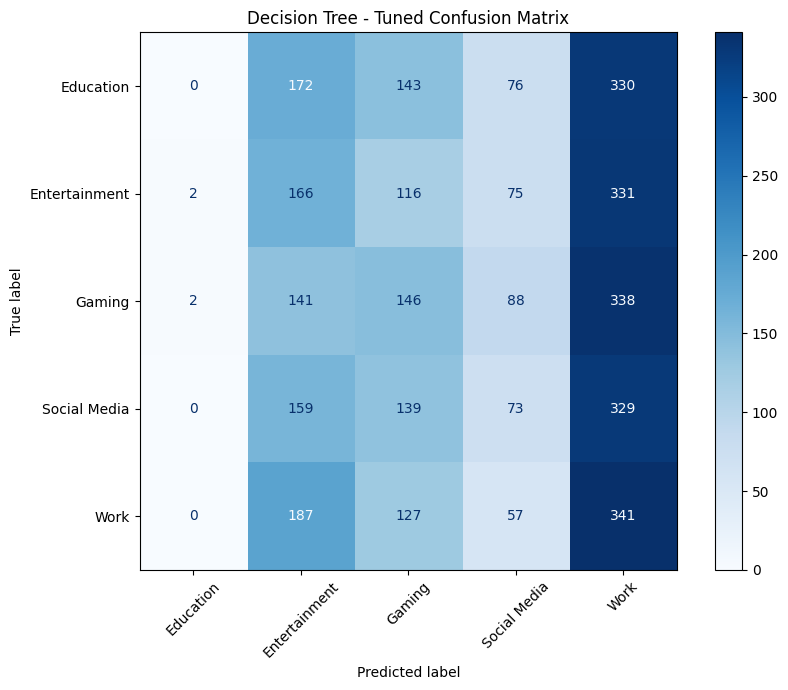

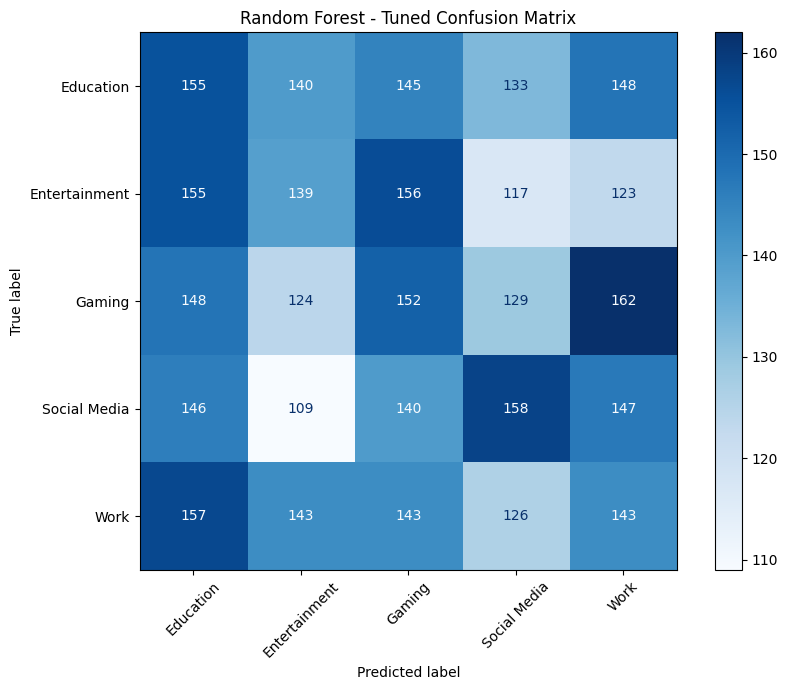

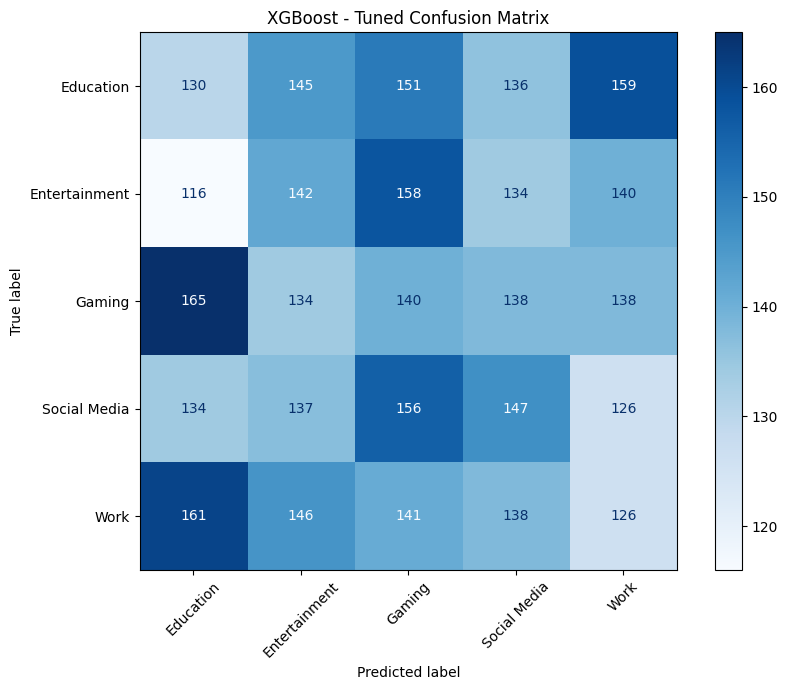

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = label_encoder.classes_

for name, model in tuned_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot
    fig, ax = plt.subplots(figsize=(9, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        xticks_rotation=45,
        cmap="Blues"
    )

    ax.set_title(f"{name} - Tuned Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:
| Model               | Before Tuning | After Tuning |
| ------------------- | ------------: | -----------: |
| Logistic Regression |        19.67% |       19.56% |
| Decision Tree       |        20.04% |       20.52% |
| Random Forest       |        20.07% |       21.11% |
| XGBoost             |        20.41% |       19.36% |


In [39]:
import joblib

# Get the tuned Random Forest pipeline
best_model = tuned_models["Random Forest"]

# Save the complete pipeline
joblib.dump(best_model, "random_forest_primary_use.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [40]:
joblib.dump(label_encoder, "label_encoder.pkl")

print("Label encoder saved successfully!")

Label encoder saved successfully!
